# Fraud Detection on Imbalanced Data
**Objective:** Build a machine learning pipeline that detects fraudulent transactions in a heavily imbalanced dataset, with class imbalance as the core challenge.

**Tech stack:** Python, pandas, scikit-learn, imbalanced-learn (SMOTE), matplotlib, seaborn

> **Note:** `credit_card_fraud.csv` is a practice dataset in the style of the Kaggle "Credit Card Fraud Detection" data (columns `Time`, `V1`...`V10`, `Amount`, `Class`). The real dataset has 284,807 transactions with only 492 frauds and 28 `V` columns. For your final submission, use the real one from Kaggle. The notebook works with it if you change the file name.

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Load data and class imbalance
_Checklist: what percentage of transactions are fraudulent?_

In [3]:
df = pd.read_csv("credit_card_fraud.csv")
print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum())
df.head()

Shape: (30000, 13)
Nulls: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,Amount,Class
0,36,1.2282,0.1580,-1.3077,-1.1478,0.7403,0.4586,0.7971,1.4432,1.9479,-0.9971,14.09,0
1,43,0.6455,1.2167,0.7788,0.7958,0.6798,-1.7037,-0.8442,1.0600,0.3205,-0.7221,7.83,0
2,74,0.3712,2.1298,-0.1706,0.5026,1.3088,-0.9868,-1.0222,-0.9063,0.2211,-0.8078,8.29,0
3,77,-0.0814,0.5278,1.1762,-0.3498,0.1612,-0.8318,-0.0518,2.0300,1.3259,0.6037,102.18,0
4,86,-0.0604,0.2209,1.0556,-2.8628,0.2532,0.3464,-1.1587,-1.3296,0.6627,1.4326,148.94,0


       Count  Percent
Class                
0      29760     99.2
1        240      0.8


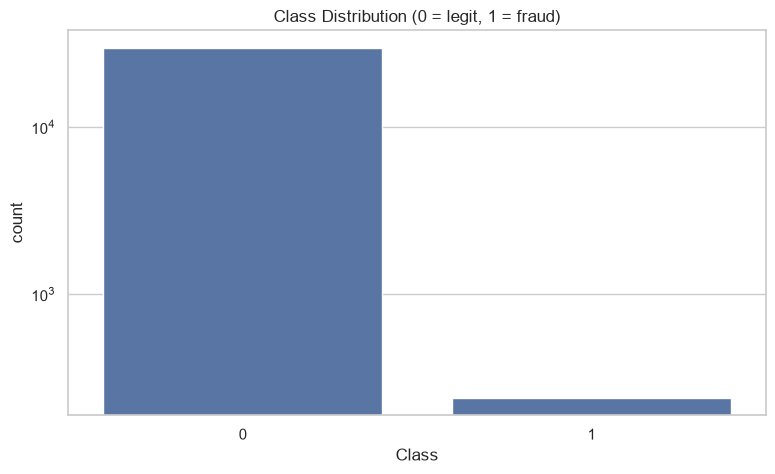

In [4]:
counts = df["Class"].value_counts()
pct = df["Class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": counts, "Percent": pct.round(3)}))

sns.countplot(data=df, x="Class")
plt.title("Class Distribution (0 = legit, 1 = fraud)")
plt.yscale("log")
plt.show()

**Observation:** _What percentage is fraud? Why is the log scale used for this chart?_

## 2. EDA
_Checklist: transaction amounts for fraud vs. non-fraud; time-of-day analysis_

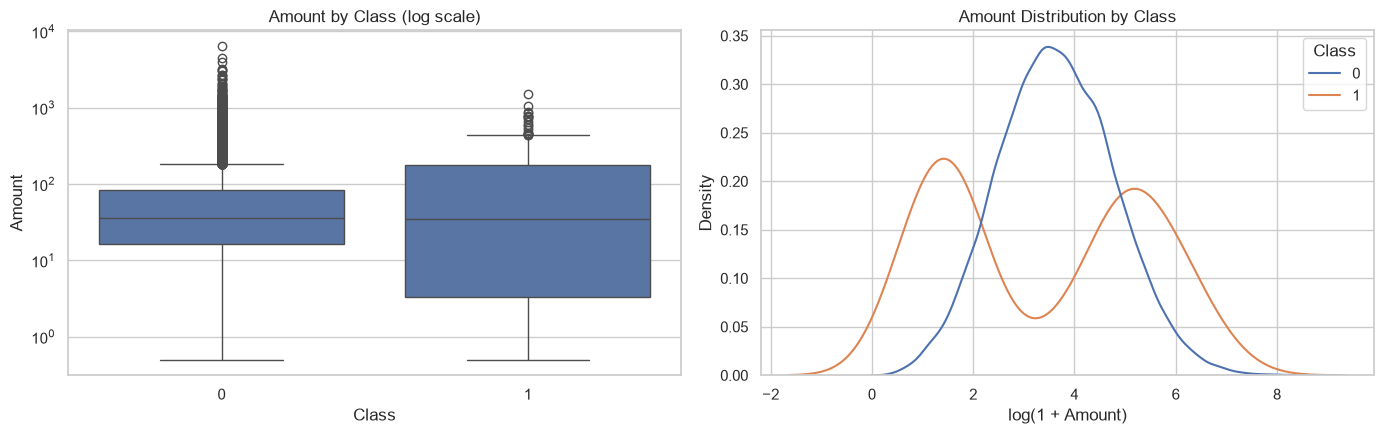

         count    mean     std  min    25%    50%     75%      max
Class                                                             
0      29760.0   75.05  138.95  0.5  16.23  36.41   82.79  6413.28
1        240.0  135.52  211.81  0.5   3.28  34.35  178.29  1520.58


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Class", y="Amount", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Amount by Class (log scale)")

sns.kdeplot(data=df, x=np.log1p(df["Amount"]), hue="Class", common_norm=False, ax=axes[1])
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_title("Amount Distribution by Class")
plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe().round(2))

**Observation:** _Write 2-3 sentences about what this output shows._

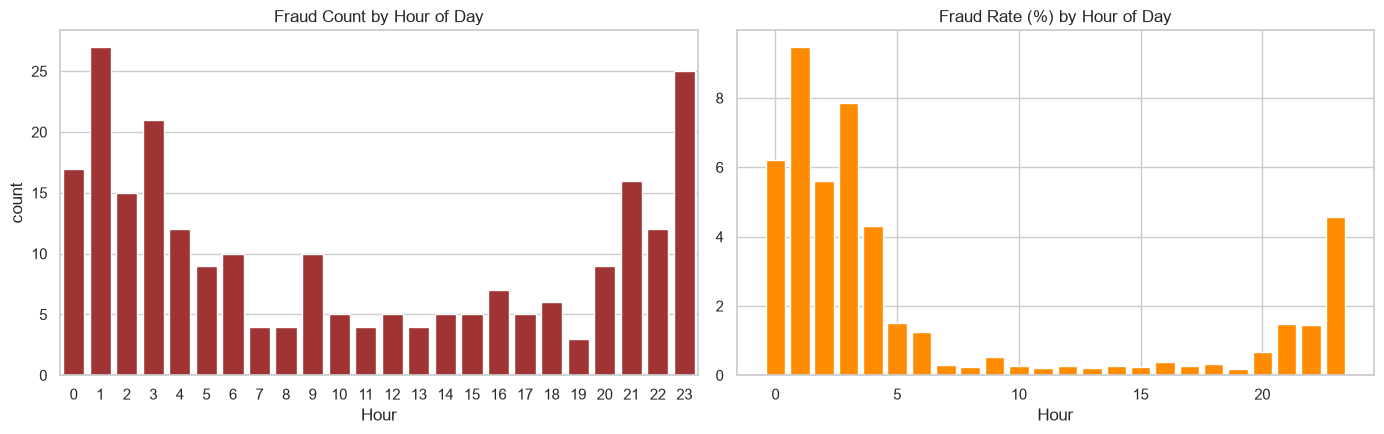

In [6]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

hourly = df.groupby("Hour")["Class"].agg(["sum", "count"])
hourly["fraud_rate_%"] = hourly["sum"] / hourly["count"] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df[df["Class"] == 1], x="Hour", ax=axes[0], color="firebrick")
axes[0].set_title("Fraud Count by Hour of Day")
axes[1].bar(hourly.index, hourly["fraud_rate_%"], color="darkorange")
axes[1].set_title("Fraud Rate (%) by Hour of Day")
axes[1].set_xlabel("Hour")
plt.tight_layout()
plt.show()

**Observation:** _At what times of day is fraud most likely? What does that suggest for a fraud team?_

## 3. Why accuracy is misleading
_Checklist: explain in your own words_

In [7]:
# A 'model' that always predicts 'not fraud'
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(df[["Amount"]], df["Class"])
p = dummy.predict(df[["Amount"]])

print("Accuracy:", round(accuracy_score(df["Class"], p), 4))
print("Recall  :", round(recall_score(df["Class"], p), 4))

Accuracy: 0.992
Recall  : 0.0


**Explanation:** _Look at the accuracy and recall above. Explain why a model that never catches any fraud can still look 'very accurate', and why that makes accuracy a bad metric here._

## 4. Prepare features and split
_Checklist: stratified split so fraud appears in both train and test_

In [8]:
df_model = df.drop(columns=["Hour"])
df_model["Amount"] = StandardScaler().fit_transform(df_model[["Amount"]])
df_model["Time"] = StandardScaler().fit_transform(df_model[["Time"]])

X = df_model.drop(columns="Class")
y = df_model["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train fraud:", y_train.sum(), "/", len(y_train))
print("Test fraud: ", y_test.sum(), "/", len(y_test))

Train fraud: 192 / 24000
Test fraud:  48 / 6000


## 5. Handle the class imbalance
_Checklist: SMOTE, undersampling, or class_weight='balanced'_

**Important:** resampling is applied **only to the training data, after the split**. The test set must keep the real-world imbalance, otherwise the evaluation is unrealistic and results leak from train to test.

_In your own words, explain how SMOTE creates new samples and what its risks are._

In [9]:
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_sm.value_counts().to_dict())

Before SMOTE: {0: 23808, 1: 192}
After SMOTE:  {0: 23808, 1: 23808}


## 6. Train the models
_Checklist: Logistic Regression + Random Forest_

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

preds, probas = {}, {}
for name, model in models.items():
    model.fit(X_train_sm, y_train_sm)
    preds[name] = model.predict(X_test)
    probas[name] = model.predict_proba(X_test)[:, 1]
    print(name, "trained")

Logistic Regression trained
Random Forest trained


## 7. Evaluate
_Checklist: precision, recall, F1, AUC-ROC (not just accuracy)_

In [11]:
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1": f1_score(y_test, preds[name]),
        "AUC-ROC": roc_auc_score(y_test, probas[name]),
        "Accuracy": accuracy_score(y_test, preds[name]),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Precision,Recall,F1,AUC-ROC,Accuracy
Model,,,,,
Logistic Regression,0.568,0.958,0.713,0.997,0.994
Random Forest,0.854,0.854,0.854,0.999,0.998


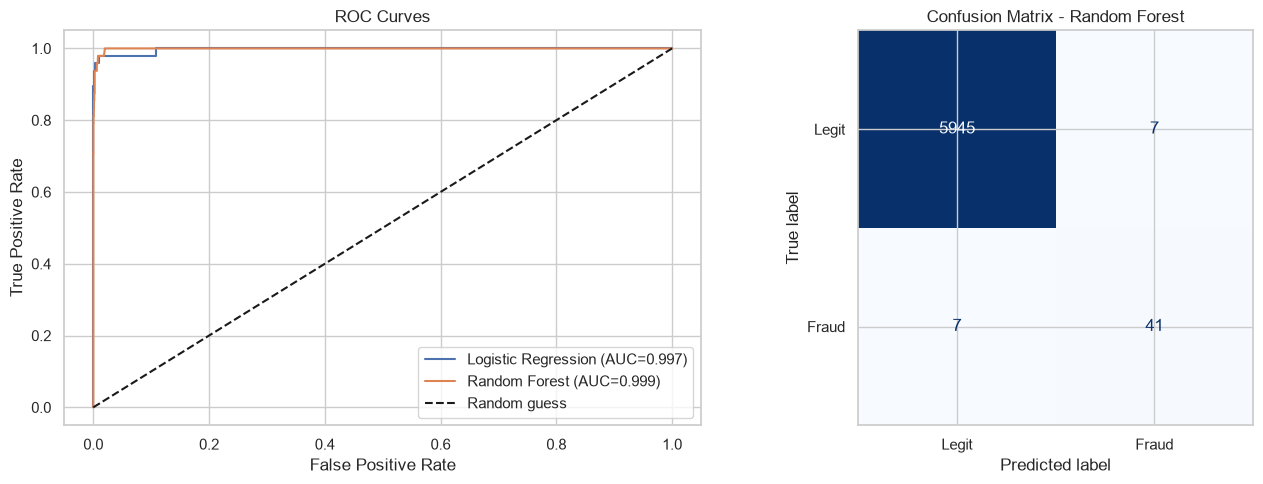

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves")
axes[0].legend()

best = results["F1"].idxmax()
cm = confusion_matrix(y_test, preds[best])
ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"Confusion Matrix - {best}")
plt.tight_layout()
plt.show()

**Observation:** _Which model is better and on which metric? Read the confusion matrix: how many frauds were caught and how many were missed? How many legitimate transactions were wrongly flagged?_

## 8. Which metric matters most?
_Checklist: Recall vs. Precision trade-off_

_Write your answer. Think about:_
- _What does a missed fraud (false negative) cost a bank?_
- _What does a false alarm (false positive) cost? Think about customers whose cards get blocked._
- _Which of the two would you prioritise, and how could you change the decision threshold to move between them?_

In [13]:
# Optional: see how the decision threshold changes precision and recall
best_proba = probas[best]
thr_rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (best_proba >= t).astype(int)
    thr_rows.append({"Threshold": t,
                     "Precision": precision_score(y_test, pred_t, zero_division=0),
                     "Recall": recall_score(y_test, pred_t)})
pd.DataFrame(thr_rows).round(3)

,Threshold,Precision,Recall
0,0.1,0.311,0.979
1,0.3,0.703,0.938
2,0.5,0.854,0.854
3,0.7,0.974,0.792
4,0.9,1.000,0.667


## 9. Feature importance
_Checklist: feature importance or coefficient analysis_

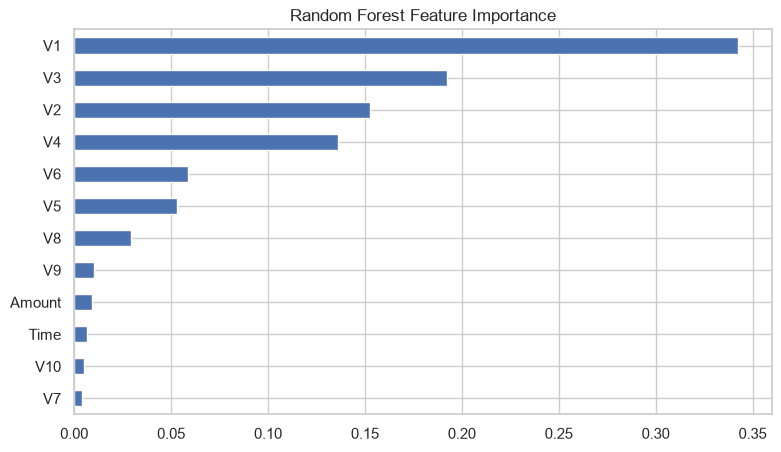

In [14]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

imp.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.show()

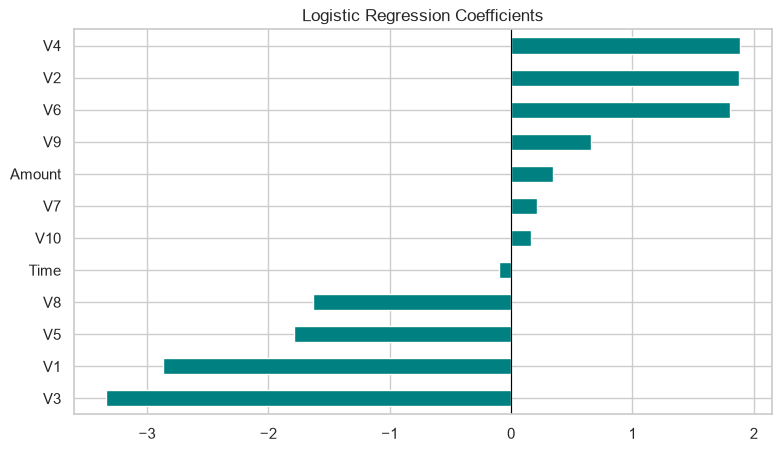

In [15]:
lr = models["Logistic Regression"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()

coef.plot(kind="barh", color="teal")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Coefficients")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 10. Scalability
_Checklist: how would this handle 1 million transactions per hour?_

_Write your discussion. Ideas to think about:_
- _1 million per hour is about 280 transactions per second. Can the model score that fast?_
- _Prediction is cheap, training is expensive: how often would you retrain?_
- _Streaming tools (Kafka, Spark), batch vs. real-time scoring, a lighter model for the first pass..._
- _Concept drift: fraudsters change behaviour over time._

## 11. Conclusion
_Summarise: how imbalanced is the data, which technique and model worked best, which metrics you trust, and what you would improve._